# Telco Customer Churn – Milestone 2: Models, Tuning and Evaluation

**Student ID:** 202300329

This notebook repeats the Milestone 1 data preparation (same seed, same steps) so it runs on its own, then trains, tunes and evaluates the models.

## 1. Data preparation 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, ConfusionMatrixDisplay, f1_score, recall_score, precision_score, accuracy_score, roc_auc_score
from sklearn.metrics import make_scorer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

STUDENT_ID = 202300329

# Load and draw the personalised subsample (stratified 80%, seed = student ID)
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df_p, _ = train_test_split(df, train_size=0.8, stratify=df["Churn"], random_state=STUDENT_ID)
df_p = df_p.reset_index(drop=True)

# Cleaning (explained in Milestone 1)
df_p = df_p.drop(columns="customerID")
df_p = df_p.replace({"No internet service": "No", "No phone service": "No"})
df_p["TotalCharges"] = pd.to_numeric(df_p["TotalCharges"], errors="coerce").fillna(0.0)
df_p["Churn"] = df_p["Churn"].map({"No": 0, "Yes": 1})

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = df_p.select_dtypes(exclude="number").columns.tolist()

# Train/test split (seed = student ID)
X, y = df_p.drop(columns="Churn"), df_p["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=STUDENT_ID)
print("Train:", X_train.shape, " Test:", X_test.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

## 2. Unsupervised feature engineering: K-Means clusters

K-Means groups customers by tenure and charges without looking at churn. The cluster number is then added as a new feature. K-Means is fitted on the **training set only** and then used to label the test set.

In [ ]:
# Pick the number of clusters with the silhouette score (higher = better separated)
scaled = StandardScaler().fit_transform(X_train[num_cols])
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=STUDENT_ID).fit_predict(scaled)
    print(f"k={k}  silhouette={silhouette_score(scaled, labels):.3f}")

k=2  silhouette=0.475


k=3  silhouette=0.454


k=4  silhouette=0.477


k=5  silhouette=0.449


k=6  silhouette=0.440


In [ ]:
K = 4   # highest silhouette score above
kmeans = make_pipeline(StandardScaler(), KMeans(n_clusters=K, n_init=10, random_state=STUDENT_ID))
X_train["Cluster"] = kmeans.fit_predict(X_train[num_cols]).astype(str)
X_test["Cluster"] = kmeans.predict(X_test[num_cols]).astype(str)

# What each cluster looks like, and how often its customers churn
summary = X_train.groupby("Cluster")[num_cols].mean().round(1)
summary["Churn rate"] = y_train.groupby(X_train["Cluster"]).mean().round(3)
summary["Customers"] = X_train["Cluster"].value_counts()
summary

,tenure,MonthlyCharges,TotalCharges,Churn rate,Customers
Cluster,,,,,
0,54.2,33.8,1802.3,0.049,741
1,15.7,81.1,1278.1,0.483,1486
2,59.6,93.3,5550.4,0.150,1217
3,10.1,31.9,300.9,0.245,1063


K = 4 gives the highest silhouette score (0.477). The four clusters are easy to describe:

- **Cluster 0:** long-term, low-cost customers, with a churn rate of only **4.9%**
- **Cluster 1:** fairly new customers with high monthly bills, with a churn rate of **48.3%**
- **Cluster 2:** long-term customers with high bills, with a churn rate of 15.0%
- **Cluster 3:** brand-new customers with low bills, with a churn rate of 24.5%

K-Means never saw the churn labels, yet it found a clear high-risk group (Cluster 1).

## 3. Pre-processing and cross-validation setup

In [ ]:
def make_preprocessor(cats):
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cats),
    ], remainder="drop")

# SeniorCitizen is already 0/1, so it is added to the categorical list (encoded as one 0/1 column)
base_cats = cat_cols + ["SeniorCitizen"]
cluster_cats = base_cats + ["Cluster"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=STUDENT_ID)
scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

def cv_scores(model, cats):
    pipe = make_pipeline(make_preprocessor(cats), model)
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    return {m: round(res[f"test_{m}"].mean(), 3) for m in scoring}

## 4. Models before tuning (5-fold cross-validation on the training set)

- **Dummy baseline:** always predicts the majority class ("No churn"). Any real model must beat this.
- **Logistic Regression** and **Random Forest**, each with and without the K-Means cluster feature.

Both real models use `class_weight="balanced"` because only 26.5% of customers churn.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=STUDENT_ID),
}

results = {"Dummy (majority class)": cv_scores(DummyClassifier(), base_cats)}
for name, model in models.items():
    results[name] = cv_scores(model, base_cats)
    results[name + " + Cluster"] = cv_scores(model, cluster_cats)

pd.DataFrame(results).T

,accuracy,precision,recall,f1,roc_auc
Dummy (majority class),0.735,0.000,0.000,0.000,0.500
Logistic Regression,0.751,0.521,0.804,0.632,0.849
Logistic Regression + Cluster,0.754,0.525,0.804,0.635,0.849
Random Forest,0.781,0.576,0.666,0.617,0.835
Random Forest + Cluster,0.778,0.571,0.661,0.613,0.834


**Cross-validation results (before tuning):**

- The Dummy model gets 73.5% accuracy but an F1 of 0, because it never predicts churn.
- Logistic Regression has the best F1 (0.632) and recall (0.804) before tuning. Random Forest has higher accuracy but misses more churners.
- Adding the K-Means cluster made almost no difference (Logistic Regression +0.003 F1, Random Forest −0.004). This makes sense: the clusters are built from tenure and charges, which the models already see. The cluster feature is kept for the tuned models because it is interpretable and does not hurt performance.

## 5. Hyperparameter tuning (Grid Search, optimising F1)

In [ ]:
CATS = cluster_cats   # keep the K-Means cluster feature (see section 4)

lr_grid = GridSearchCV(
    make_pipeline(make_preprocessor(CATS), LogisticRegression(class_weight="balanced", max_iter=1000)),
    {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    cv=cv, scoring="f1", n_jobs=-1)
lr_grid.fit(X_train, y_train)

rf_grid = GridSearchCV(
    make_pipeline(make_preprocessor(CATS), RandomForestClassifier(class_weight="balanced", random_state=STUDENT_ID)),
    {"randomforestclassifier__n_estimators": [100, 300],
     "randomforestclassifier__max_depth": [5, 10, None],
     "randomforestclassifier__min_samples_leaf": [1, 5, 10]},
    cv=cv, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train, y_train)

for name, grid in [("Logistic Regression", lr_grid), ("Random Forest", rf_grid)]:
    print(f"{name}: best CV F1 = {grid.best_score_:.3f}  params = {grid.best_params_}")

Logistic Regression: best CV F1 = 0.635  params = {'logisticregression__C': 10}
Random Forest: best CV F1 = 0.639  params = {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__n_estimators': 300}


**Tuning results:**

- **Logistic Regression:** best `C = 10`. CV F1 stayed about the same (0.635 before and after), so the default settings were already close to optimal.
- **Random Forest:** best settings are `n_estimators = 300`, `max_depth = None`, `min_samples_leaf = 10`. CV F1 improved from **0.613 to 0.639**. Requiring at least 10 customers per leaf stops the trees memorising the training data, which reduces overfitting.

## 6. Final evaluation on the test set (used once, after tuning)

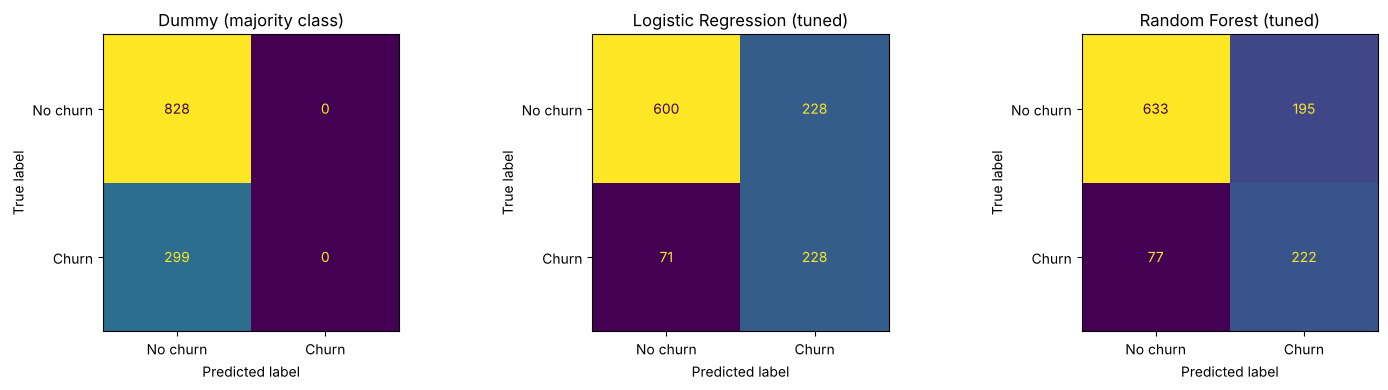

,accuracy,precision,recall,f1,roc_auc
Dummy (majority class),0.735,0.000,0.000,0.000,0.500
Logistic Regression (tuned),0.735,0.500,0.763,0.604,0.826
Random Forest (tuned),0.759,0.532,0.742,0.620,0.830


In [ ]:
final_models = {"Dummy (majority class)": make_pipeline(make_preprocessor(CATS), DummyClassifier()).fit(X_train, y_train),
                "Logistic Regression (tuned)": lr_grid.best_estimator_,
                "Random Forest (tuned)": rf_grid.best_estimator_}

test_results = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, final_models.items()):
    pred = model.predict(X_test)
    test_results[name] = {"accuracy": accuracy_score(y_test, pred),
                          "precision": precision_score(y_test, pred, zero_division=0),
                          "recall": recall_score(y_test, pred),
                          "f1": f1_score(y_test, pred),
                          "roc_auc": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])}
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No churn", "Churn"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

pd.DataFrame(test_results).T.round(3)

**Test-set results:**

- The Dummy model gets **73.5% accuracy but finds 0 churners**. This shows why accuracy alone is misleading here, and why F1 and recall are the main metrics.
- **Tuned Random Forest is the best model:** F1 = 0.620, recall = 0.742, ROC-AUC = 0.830. It catches 222 of the 299 churners.
- Logistic Regression is close behind (F1 = 0.604). It catches slightly more churners (recall 0.763), but raises more false alarms (228 vs 195).
- Test scores are a little lower than the cross-validation scores (about 0.62 vs 0.64), which is normal for unseen data and shows no sign of serious overfitting.

## 7. Which features matter most? (Random Forest)

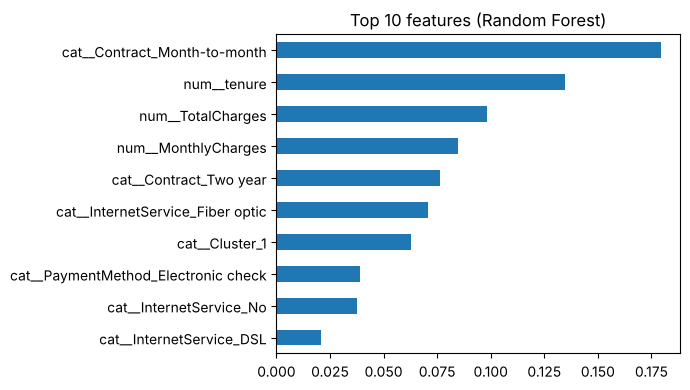

In [ ]:
rf = rf_grid.best_estimator_
importances = pd.Series(rf[-1].feature_importances_, index=rf[0].get_feature_names_out())
importances.sort_values().tail(10).plot.barh(figsize=(7, 4), title="Top 10 features (Random Forest)")
plt.tight_layout(); plt.show()

The most important features match the Milestone 1 EDA: month-to-month contracts, short tenure, charges, fiber optic internet and electronic check payments. The K-Means **Cluster 1** (new customers with high bills) also appears in the top 10, so the unsupervised feature was used by the model.